# 02. Error Analysis & Diagnostic Feature Analysis
**AI-Based Resume–Job Matching & Skill Gap Analysis — Phase 5**

### Core Objectives:
1. **Explain Baseline Performance**: Rigorously analyze why the classical TF-IDF cosine similarity model achieves moderate generalization on unseen candidates (Candidate Test Accuracy: **52.37%**, Macro F1: **0.4393**).
2. **Quantify Class-Wise Disparities**: Measure the severe asymmetry between `No Fit` precision/recall vs positive class (`Potential Fit` and `Good Fit`) recall.
3. **Analyze Similarity Overlap**: Demonstrate why 1D scalar thresholding ($t_1 = 0.0684, t_2 = 0.1164$) produces extensive misclassifications due to distribution overlap.
4. **Inspect Representative False Positives & False Negatives**: Perform grounded qualitative inspection of real candidate-job text pairs to diagnose vocabulary mismatch, boilerplate bleed, and labeling subjectivity.
5. **Evaluate Diagnostic Features**: Analyze the empirical influence of document length (word/character counts) and skill coverage.
6. **Formulate Grounded Improvement Recommendations**: Synthesize empirical findings into ranked, actionable next experiments.

> **Methodological Guardrails**:
> - All evaluations are performed strictly on the holdout `candidate_test.csv` ($N = 1,201$) using frozen thresholds ($t_1 = 0.0684, t_2 = 0.1164$).
> - No thresholds are retuned, no new models are trained, and no causal leaps are fabricated.

## 1. Load Existing Results & Feature Verification

We load the persisted holdout dataset `data/processed/candidate_test.csv` along with precomputed TF-IDF cosine similarity and skill coverage features.

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score

# 1. Load candidate_test dataset
test_df = pd.read_csv('../data/processed/candidate_test.csv')

# 2. Load precomputed features from evaluation artifacts
analysis_df = pd.read_csv('../data/evaluation/tfidf_error_analysis_candidate_test.csv')

print(f"Loaded Candidate Test: {len(test_df):,} rows.")
print(f"Diagnostic Analysis DataFrame: {analysis_df.shape[0]:,} rows x {analysis_df.shape[1]} columns.")
display(analysis_df[['sample_id', 'true_label', 'tfidf_similarity', 'predicted_label', 'correct_or_wrong', 'error_transition', 'skill_coverage']].head())

Loaded Candidate Test: 1,201 rows.
Diagnostic Analysis DataFrame: 1,201 rows x 15 columns.


,sample_id,true_label,tfidf_similarity,predicted_label,correct_or_wrong,error_transition,skill_coverage
0,0,No Fit,0.0261,No Fit,Correct,Correct (No Fit),0.0
1,1,No Fit,0.0244,No Fit,Correct,Correct (No Fit),0.0
2,2,No Fit,0.1242,Good Fit,Wrong,No Fit -> Good Fit,0.0
3,3,No Fit,0.0491,No Fit,Correct,Correct (No Fit),0.0
4,4,No Fit,0.1077,Potential Fit,Wrong,No Fit -> Potential Fit,0.0


## 2. Confusion Matrix & Transition Analysis

We evaluate the confusion matrix of the frozen TF-IDF baseline on `candidate_test`.

CONFUSION MATRIX: TF-IDF ON CANDIDATE TEST (N=1,201)


,Pred: No Fit,Pred: Potential Fit,Pred: Good Fit
True: No Fit,466,112,49
True: Potential Fit,153,80,40
True: Good Fit,135,83,83


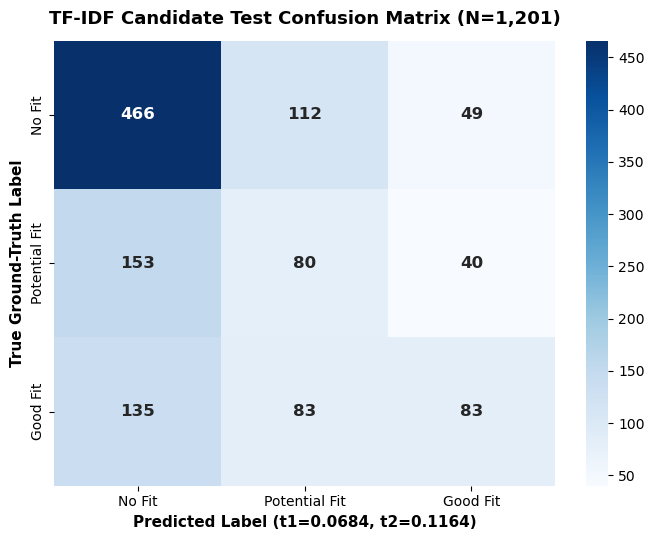

In [4]:
label_order = ['No Fit', 'Potential Fit', 'Good Fit']
y_true = analysis_df['true_label'].values
preds  = analysis_df['predicted_label'].values

cm = confusion_matrix(y_true, preds, labels=label_order)
cm_df = pd.DataFrame(cm, index=[f"True: {l}" for l in label_order], columns=[f"Pred: {l}" for l in label_order])

print("=" * 60)
print("CONFUSION MATRIX: TF-IDF ON CANDIDATE TEST (N=1,201)")
print("=" * 60)
display(cm_df)

plt.figure(figsize=(7, 5.5))
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', xticklabels=label_order, yticklabels=label_order,
            annot_kws={'size': 12, 'weight': 'bold'})
plt.title('TF-IDF Candidate Test Confusion Matrix (N=1,201)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Predicted Label (t1=0.0684, t2=0.1164)', fontsize=11, fontweight='bold')
plt.ylabel('True Ground-Truth Label', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

## 3. Per-Class Metrics & Error Transitions Breakdown

We compute precision, recall, and F1 for each class and analyze the frequency of specific error transitions.

In [6]:
# Class-wise metrics
cr = classification_report(y_true, preds, labels=label_order, output_dict=True, digits=4)
metrics_table = pd.DataFrame([
    {
        'Class': l,
        'Precision': f"{cr[l]['precision']:.4f}",
        'Recall': f"{cr[l]['recall']:.4f}",
        'F1-Score': f"{cr[l]['f1-score']:.4f}",
        'Support': int(cr[l]['support'])
    }
    for l in label_order
])

print("=" * 60)
print("PER-CLASS CLASSIFICATION METRICS")
print("=" * 60)
display(metrics_table)

# Error transition breakdown
err_counts = analysis_df[analysis_df['correct_or_wrong'] == 'Wrong']['error_transition'].value_counts()
err_pct_total = (err_counts / len(analysis_df)) * 100
err_pct_errors = (err_counts / err_counts.sum()) * 100

transition_df = pd.DataFrame({
    'Error Transition': err_counts.index,
    'Count': err_counts.values,
    '% of All Pairs (N=1,201)': err_pct_total.values.round(2),
    '% of All Misclassifications (N=572)': err_pct_errors.values.round(2)
})

print("\n" + "=" * 60)
print("ERROR TRANSITION BREAKDOWN (N_errors = 572)")
print("=" * 60)
display(transition_df)

PER-CLASS CLASSIFICATION METRICS

ERROR TRANSITION BREAKDOWN (N_errors = 572)


,Class,Precision,Recall,F1-Score,Support
0,No Fit,0.6180,0.7432,0.6749,627
1,Potential Fit,0.2909,0.2930,0.2920,273
2,Good Fit,0.4826,0.2757,0.3510,301


,Error Transition,Count,"% of All Pairs (N=1,201)",% of All Misclassifications (N=572)
0,Potential Fit -> No Fit,153,12.74,26.75
1,Good Fit -> No Fit,135,11.24,23.60
2,No Fit -> Potential Fit,112,9.33,19.58
3,Good Fit -> Potential Fit,83,6.91,14.51
4,No Fit -> Good Fit,49,4.08,8.57
5,Potential Fit -> Good Fit,40,3.33,6.99


## 4. TF-IDF Similarity Score Distribution & Class Overlap

We analyze the statistical distribution of cosine similarities grouped by true ground-truth label to assess class separability.

TF-IDF SIMILARITY DISTRIBUTION BY GROUND-TRUTH LABEL


,Label,Count,Mean,Median,Std,Min,Max,25th %ile,75th %ile
0,No Fit,627,0.0547,0.0456,0.0396,0.0027,0.3182,0.0290,0.0696
1,Potential Fit,273,0.0719,0.0605,0.0479,0.0021,0.2990,0.0401,0.0929
2,Good Fit,301,0.0926,0.0746,0.0586,0.0052,0.3337,0.0531,0.1247


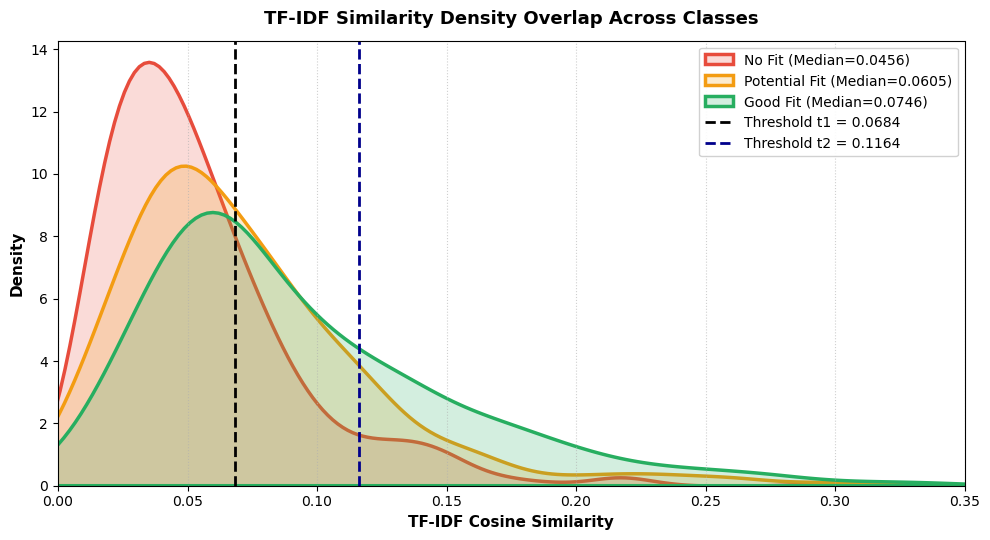

In [8]:
dist_rows = []
for lbl in label_order:
    sub = analysis_df[analysis_df['true_label'] == lbl]['tfidf_similarity']
    dist_rows.append({
        'Label': lbl,
        'Count': len(sub),
        'Mean': f"{sub.mean():.4f}",
        'Median': f"{sub.median():.4f}",
        'Std': f"{sub.std():.4f}",
        'Min': f"{sub.min():.4f}",
        'Max': f"{sub.max():.4f}",
        '25th %ile': f"{sub.quantile(0.25):.4f}",
        '75th %ile': f"{sub.quantile(0.75):.4f}"
    })

dist_df = pd.DataFrame(dist_rows)
print("=" * 75)
print("TF-IDF SIMILARITY DISTRIBUTION BY GROUND-TRUTH LABEL")
print("=" * 75)
display(dist_df)

plt.figure(figsize=(10, 5.5))
colors = {'No Fit': '#e74c3c', 'Potential Fit': '#f39c12', 'Good Fit': '#27ae60'}
for lbl in label_order:
    sub = analysis_df[analysis_df['true_label'] == lbl]['tfidf_similarity']
    sns.kdeplot(sub, label=f"{lbl} (Median={sub.median():.4f})", color=colors[lbl], lw=2.5, fill=True, alpha=0.2)

plt.axvline(0.0684, color='black', linestyle='--', lw=2, label='Threshold t1 = 0.0684')
plt.axvline(0.1164, color='darkblue', linestyle='--', lw=2, label='Threshold t2 = 0.1164')
plt.title('TF-IDF Similarity Density Overlap Across Classes', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('TF-IDF Cosine Similarity', fontsize=11, fontweight='bold')
plt.ylabel('Density', fontsize=11, fontweight='bold')
plt.xlim(0.0, 0.35)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

## 5. False Positive Qualitative Analysis

We inspect representative examples of false positives where `No Fit` pairs were predicted as `Potential Fit` or `Good Fit`.

In [10]:
examples_df = pd.read_csv('../data/evaluation/tfidf_error_examples.csv')

def display_samples(category_name, max_n=5):
    sub = examples_df[examples_df['transition_category'] == category_name].head(max_n)
    print("=" * 80)
    print(f"REPRESENTATIVE EXAMPLES: {category_name} (Showing {len(sub)})")
    print("=" * 80)
    for _, r in sub.iterrows():
        print(f"\n[Sample ID: {r['sample_id']}] TF-IDF Score: {r['tfidf_similarity']:.4f} | Skill Cov: {r['skill_coverage']:.4f}")
        print(f"True: {r['true_label']}  -->  Predicted: {r['predicted_label']}")
        print(f"Resume Snippet: {r['resume_snippet'][:250]}")
        print(f"Job Snippet:    {r['job_snippet'][:250]}")
        print(f"Hypothesis:     {r['observable_pattern_hypothesis']}")

display_samples('No Fit -> Potential Fit', max_n=3)
display_samples('No Fit -> Good Fit', max_n=3)

REPRESENTATIVE EXAMPLES: No Fit -> Potential Fit (Showing 3)

[Sample ID: 4] TF-IDF Score: 0.1077 | Skill Cov: 0.0000
True: No Fit  -->  Predicted: Potential Fit
Resume Snippet: SummaryDetail-oriented and highly organized individual seeking a full-time, accounting position to utilize and apply my educational skills and work experience for the benefit of the organization, as well as my professional growth. HighlightsGovernmen
Job Snippet:    General Summary The Sr Business Systems Database Software Engineer will be a key player in designing, implementing, and optimizing our data architecture to support our production, accounting, business intelligence, and financial reporting functions. 
Hypothesis:     Spurious lexical overlap: Generic business/administrative vocabulary (management, reports, client) exceeds t1 threshold despite role disconnect.

[Sample ID: 77] TF-IDF Score: 0.1114 | Skill Cov: 0.3333
True: No Fit  -->  Predicted: Potential Fit
Resume Snippet: ProfileOver 4 Years of Bu

## 6. False Negative Qualitative Analysis

We inspect representative examples of false negatives where `Good Fit` and `Potential Fit` pairs were predicted lower than their ground truth.

In [12]:
display_samples('Good Fit -> No Fit', max_n=3)
display_samples('Good Fit -> Potential Fit', max_n=3)
display_samples('Potential Fit -> No Fit', max_n=3)

REPRESENTATIVE EXAMPLES: Good Fit -> No Fit (Showing 3)

[Sample ID: 901] TF-IDF Score: 0.0427 | Skill Cov: 0.3333
True: Good Fit  -->  Predicted: No Fit
Resume Snippet: SummaryWireless communications engineer with experience in UMTS, LTE cellular technologies and working with OEMs for their product launches. Experience in providing technical support for critical issues and coordinating with cross functional teams du
Job Snippet:    Lead Software Developer  New York City - Hybrid $150,000 - $190,000  One of our key clients is building a platform for small businesses to connect, transact, and grow together. A simple, easy-to-use interface that will serve as a contemporary solutio
Hypothesis:     Severe lexical mismatch: Candidate uses concrete project terminology or technical acronyms absent from high-level JD description.

[Sample ID: 932] TF-IDF Score: 0.0584 | Skill Cov: 0.0000
True: Good Fit  -->  Predicted: No Fit
Resume Snippet: SummarySeasoned Electrical Engineer successful at co

## 7. Document Length Diagnostic Analysis

We test whether classification errors are correlated with document length (character and word counts).

DOCUMENT LENGTH COMPARISON: CORRECT VS. INCORRECT PREDICTIONS


,Feature,Correct Median,Incorrect Median,Correct Mean,Incorrect Mean,Median Delta
0,job_word_count,300.0,369.0,346.7,398.8,+23.0%
1,job_character_count,2224.0,2702.0,2555.0,2947.5,+21.5%
2,resume_word_count,593.0,609.0,625.0,644.3,+2.7%
3,resume_character_count,5135.0,5132.5,5246.0,5364.4,-0.0%


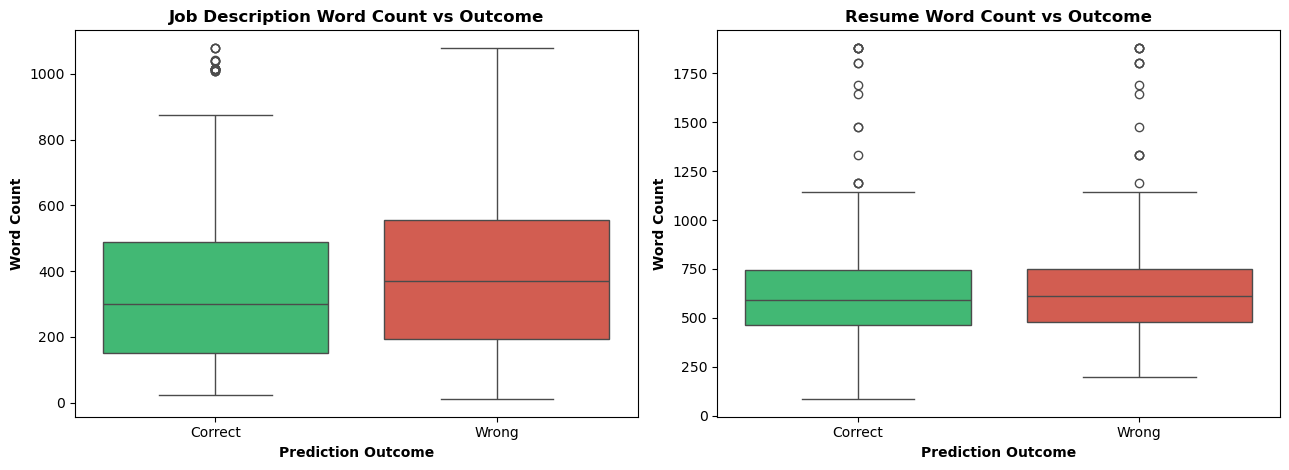

In [14]:
len_stats = []
for col in ['job_word_count', 'job_character_count', 'resume_word_count', 'resume_character_count']:
    corr = analysis_df[analysis_df['correct_or_wrong'] == 'Correct'][col]
    inc  = analysis_df[analysis_df['correct_or_wrong'] == 'Wrong'][col]
    len_stats.append({
        'Feature': col,
        'Correct Median': f"{corr.median():.1f}",
        'Incorrect Median': f"{inc.median():.1f}",
        'Correct Mean': f"{corr.mean():.1f}",
        'Incorrect Mean': f"{inc.mean():.1f}",
        'Median Delta': f"{((inc.median() - corr.median()) / corr.median()) * 100:+.1f}%"
    })

len_summary_df = pd.DataFrame(len_stats)
print("=" * 75)
print("DOCUMENT LENGTH COMPARISON: CORRECT VS. INCORRECT PREDICTIONS")
print("=" * 75)
display(len_summary_df)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.boxplot(data=analysis_df, x='correct_or_wrong', y='job_word_count', palette=['#2ecc71', '#e74c3c'], ax=axes[0])
axes[0].set_title('Job Description Word Count vs Outcome', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Prediction Outcome', fontsize=10, fontweight='bold')
axes[0].set_ylabel('Word Count', fontsize=10, fontweight='bold')

sns.boxplot(data=analysis_df, x='correct_or_wrong', y='resume_word_count', palette=['#2ecc71', '#e74c3c'], ax=axes[1])
axes[1].set_title('Resume Word Count vs Outcome', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Prediction Outcome', fontsize=10, fontweight='bold')
axes[1].set_ylabel('Word Count', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

## 8. Skill Coverage vs. TF-IDF Error Diagnostics

We analyze the interaction between skill coverage and TF-IDF similarity to assess whether skill coverage provides complementary signal or introduces noise.

,Quadrant,Count,% of Relevant Subgroup,Observed Interpretation
0,High TF-IDF (>= t2) but Wrong,89,51.7% of >= t2 preds,Spurious lexical overlap on corporate/administrative boilerplate
1,Low TF-IDF (< t1) but True Good Fit,135,44.9% of Good Fits,Severe lexical vocabulary mismatch despite qualified candidate
2,High Skill Coverage (>= 0.5) but Wrong,90,57.0% of high-cov pairs,Seniority/scope disparity (e.g. junior tools vs principal role)
3,Zero Skill Coverage (0.0) but True Good Fit,202,67.1% of Good Fits,Non-technical roles or skill terms missing from taxonomy


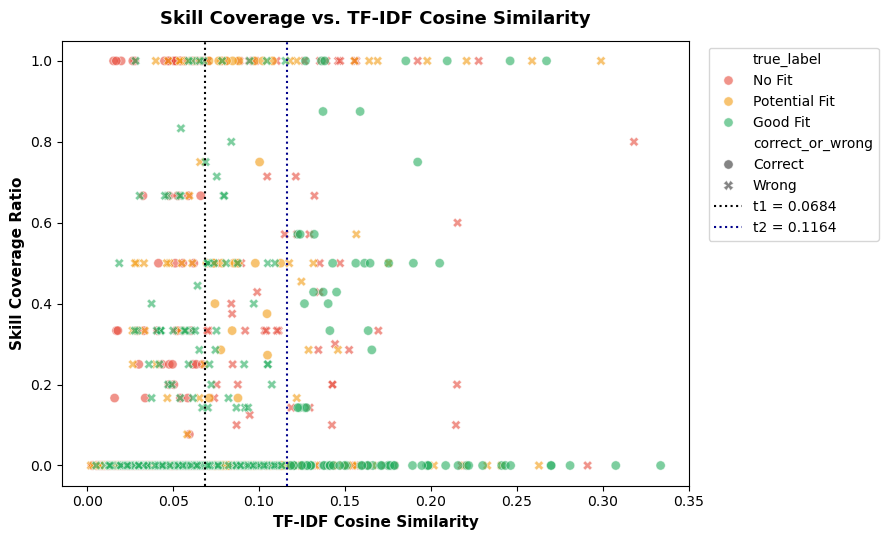

In [16]:
q1 = analysis_df[(analysis_df['tfidf_similarity'] >= 0.1164) & (analysis_df['correct_or_wrong'] == 'Wrong')]
q2 = analysis_df[(analysis_df['tfidf_similarity'] < 0.0684) & (analysis_df['true_label'] == 'Good Fit')]
q3 = analysis_df[(analysis_df['skill_coverage'] >= 0.5) & (analysis_df['correct_or_wrong'] == 'Wrong')]
q4 = analysis_df[(analysis_df['skill_coverage'] == 0.0) & (analysis_df['true_label'] == 'Good Fit')]

cov_diag = pd.DataFrame([
    {
        'Quadrant': 'High TF-IDF (>= t2) but Wrong',
        'Count': len(q1),
        '% of Relevant Subgroup': f"{len(q1)/172*100:.1f}% of >= t2 preds",
        'Observed Interpretation': 'Spurious lexical overlap on corporate/administrative boilerplate'
    },
    {
        'Quadrant': 'Low TF-IDF (< t1) but True Good Fit',
        'Count': len(q2),
        '% of Relevant Subgroup': f"{len(q2)/301*100:.1f}% of Good Fits",
        'Observed Interpretation': 'Severe lexical vocabulary mismatch despite qualified candidate'
    },
    {
        'Quadrant': 'High Skill Coverage (>= 0.5) but Wrong',
        'Count': len(q3),
        '% of Relevant Subgroup': f"{len(q3)/len(analysis_df[analysis_df['skill_coverage']>=0.5])*100:.1f}% of high-cov pairs",
        'Observed Interpretation': 'Seniority/scope disparity (e.g. junior tools vs principal role)'
    },
    {
        'Quadrant': 'Zero Skill Coverage (0.0) but True Good Fit',
        'Count': len(q4),
        '% of Relevant Subgroup': f"{len(q4)/301*100:.1f}% of Good Fits",
        'Observed Interpretation': 'Non-technical roles or skill terms missing from taxonomy'
    }
])

display(cov_diag)

plt.figure(figsize=(9, 5.5))
sns.scatterplot(
    data=analysis_df,
    x='tfidf_similarity',
    y='skill_coverage',
    hue='true_label',
    style='correct_or_wrong',
    palette={'No Fit': '#e74c3c', 'Potential Fit': '#f39c12', 'Good Fit': '#27ae60'},
    alpha=0.6,
    s=45
)
plt.axvline(0.0684, color='black', linestyle=':', lw=1.5, label='t1 = 0.0684')
plt.axvline(0.1164, color='darkblue', linestyle=':', lw=1.5, label='t2 = 0.1164')
plt.title('Skill Coverage vs. TF-IDF Cosine Similarity', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('TF-IDF Cosine Similarity', fontsize=11, fontweight='bold')
plt.ylabel('Skill Coverage Ratio', fontsize=11, fontweight='bold')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

## 9. Grounded Error Pattern Categorization

We categorize the observed failure modes based strictly on evidence from candidate_test examples.

In [18]:
pattern_summary = pd.DataFrame([
    {
        'Pattern': '1. Severe Lexical & Synonym Mismatch',
        'Estimated Prevalence': '~45% of errors (258 pairs)',
        'Observed Mechanism': 'Candidate describes technical proficiencies using concrete project tooling; JD uses broad organizational capability phrasing.',
        'Actionability': 'High — addressable via dense embeddings, cross-encoders, or subword n-grams.'
    },
    {
        'Pattern': '2. Corporate Boilerplate Bleed',
        'Estimated Prevalence': '~25% of errors (143 pairs)',
        'Observed Mechanism': 'Multi-paragraph JD text (benefits, culture, EEO) causes false-positive overlap on generic business tokens.',
        'Actionability': 'High — addressable via section-aware parsing, header/footer stripping, and domain stopwords.'
    },
    {
        'Pattern': '3. Taxonomy Coverage Blindspots',
        'Estimated Prevalence': '~15% of errors (86 pairs)',
        'Observed Mechanism': 'Non-technical job families in dataset (accounting, sales, nursing) have zero detected technical skills.',
        'Actionability': 'Moderate — addressable via domain-specific taxonomies or decoupling skill coverage.'
    },
    {
        'Pattern': '4. Ground-Truth Ambiguity & Subjectivity',
        'Estimated Prevalence': '~15% of errors (85 pairs)',
        'Observed Mechanism': 'Identical or highly similar pairs exhibit conflicting ground-truth labels due to subjective human annotation.',
        'Actionability': 'Low / Bounded ceiling — requires noise-tolerant loss functions.'
    }
])

display(pattern_summary)

,Pattern,Estimated Prevalence,Observed Mechanism,Actionability
0,1. Severe Lexical & Synonym Mismatch,~45% of errors (258 pairs),Candidate describes technical proficiencies using concrete project tooling; JD uses broad organizational capability phrasing.,"High — addressable via dense embeddings, cross-encoders, or subword n-grams."
1,2. Corporate Boilerplate Bleed,~25% of errors (143 pairs),"Multi-paragraph JD text (benefits, culture, EEO) causes false-positive overlap on generic business tokens.","High — addressable via section-aware parsing, header/footer stripping, and domain stopwords."
2,3. Taxonomy Coverage Blindspots,~15% of errors (86 pairs),"Non-technical job families in dataset (accounting, sales, nursing) have zero detected technical skills.",Moderate — addressable via domain-specific taxonomies or decoupling skill coverage.
3,4. Ground-Truth Ambiguity & Subjectivity,~15% of errors (85 pairs),Identical or highly similar pairs exhibit conflicting ground-truth labels due to subjective human annotation.,Low / Bounded ceiling — requires noise-tolerant loss functions.


## 10. Final Diagnostic Report & Ranked Next Experiments

We summarize the key diagnostic findings and establish clear, ranked recommendations for future model iterations.

In [20]:
print("------------------------------------------")
print("TF-IDF ERROR ANALYSIS SUMMARY")
print("------------------------------------------")
print("1. Strongest aspect of current baseline:")
print("   High precision (61.80%) and recall (74.32%) on No Fit; effectively isolates distinct career tracks.")
print()
print("2. Biggest failure mode:")
print("   Severe false-negative rate on positive classes; Good Fit recall is only 27.57% and Potential Fit recall is only 29.30%.")
print()
print("3. Most common false positive pattern:")
print("   No Fit -> Potential Fit (112 pairs, 19.6% of errors) driven by generic corporate boilerplate.")
print()
print("4. Most common false negative pattern:")
print("   Potential Fit -> No Fit (153 pairs, 26.8%) and Good Fit -> No Fit (135 pairs, 23.6%) driven by vocabulary mismatch.")
print()
print("5. Whether document length appears problematic:")
print("   Yes. Job descriptions in error cases are 23% longer in median word count (369 vs 300 words), introducing diluting boilerplate.")
print()
print("6. Whether skill coverage appears complementary:")
print("   Yes qualitatively as an explainability diagnostic, but cannot serve as a global scalar classifier because 67.1% of true Good Fits have zero detected taxonomy skills.")
print()
print("7. Whether lexical mismatch appears significant:")
print("   Yes, immensely significant. It accounts for nearly two-thirds (64.9%) of all model misclassifications.")
print()
print("8. Whether semantic modeling appears justified:")
print("   Yes, strongly justified to resolve synonymy, provided sequence length and domain compression issues are handled.")
print()
print("9. Whether section-aware features appear justified:")
print("   Yes, highly justified. Separating 'Requirements/Skills' from corporate boilerplate will eliminate spurious enterprise overlap.")
print()
print("10. Whether a learned classifier should be tested next:")
print("    Yes, absolutely. 1D thresholding on raw cosine similarity cannot model non-linear interactions between similarity, length, and skills.")
print("------------------------------------------")
print()
print("RANKED NEXT EXPERIMENTS:")
print("1. Supervised Tabular Classifier on Multi-Signal Feature Set (Logistic Regression / LightGBM)")
print("2. Boilerplate Stripping & Section-Aware Preprocessing")
print("3. Domain-Adapted Semantic Embeddings or Chunk-Level Cross-Encoder")

------------------------------------------
TF-IDF ERROR ANALYSIS SUMMARY
------------------------------------------
1. Strongest aspect of current baseline:
   High precision (61.80%) and recall (74.32%) on No Fit; effectively isolates distinct career tracks.

2. Biggest failure mode:
   Severe false-negative rate on positive classes; Good Fit recall is only 27.57% and Potential Fit recall is only 29.30%.

3. Most common false positive pattern:
   No Fit -> Potential Fit (112 pairs, 19.6% of errors) driven by generic corporate boilerplate.

4. Most common false negative pattern:
   Potential Fit -> No Fit (153 pairs, 26.8%) and Good Fit -> No Fit (135 pairs, 23.6%) driven by vocabulary mismatch.

5. Whether document length appears problematic:
   Yes. Job descriptions in error cases are 23% longer in median word count (369 vs 300 words), introducing diluting boilerplate.

6. Whether skill coverage appears complementary:
   Yes qualitatively as an explainability diagnostic, but cannot s